![Banner](../../../Images/Banner/09_distributed_spatial_datas.png)

# Measuring, Checking and Tuning Distributed and GPU Workloads

A fast wrong answer is worse than a slow right one, and a "speed-up" measured badly is neither.
This notebook collects the habits that kept the rest of the chapter honest: checking that CPU and
GPU give the same answer, timing what actually happens (including the GPU's asynchronous queue and
Dask's laziness), measuring strong and weak scaling, finding where the time goes with a profiler,
and recognising the common mistakes. Every pitfall in the last section actually happened while
this chapter was written, and each is reproduced and fixed with `geolattice.distributed.diagnostics`.

## Overview

### Correctness first

GPU kernels, chunked algorithms and parallel reductions all compute in a different order from the
plain whole-array version, so results can differ by rounding, and bugs show up at chunk edges, at
NaN values or with unusual geometries. Every operation should be checked against a reference on
real data before it is trusted at scale: exactly for integers and geometries, within a tolerance
for floating point.

### Timing correctly

- **Laziness**: a Dask call returns at once; time the `.compute()` (or the write) instead.
- **GPU queues**: CuPy launches kernels asynchronously; synchronise the device before stopping the
  clock.
- **Warm-up**: the first call compiles kernels, fills caches and loads files into the page cache;
  time later calls, or report the first separately.
- **Repeats**: report the best or the median of several runs.

### Strong and weak scaling

- **Strong scaling**: fixed problem, more workers. Ideal: time falls as `1/n`; Amdahl's law
  (notebook 00) describes the shortfall.
- **Weak scaling**: problem grows with the workers. Ideal: constant time. Weak scaling is what
  matters when the reason for more workers is more data.

### Overheads that eat speed-ups

Task scheduling (about a millisecond per task on a cluster), serialization between processes,
host-to-device copies over PCIe, Python code that holds the GIL, and reading the same data twice.

## Diagnostics with GeoLattice

| Function | Does |
|---|---|
| `pdist.check_equivalence(func, *args, rtol=, atol=)` | runs `func` with `compute="cpu"` and `"gpu"` and compares arrays, DataArrays, tables, GeoDataFrames and result objects |
| `pdist.benchmark(func, *args, computes=, repeats=, warmup=)` | best, mean and spread of the run time per target, lazy results materialised and the GPU synchronised |
| `pdist.explain(op, compute=)` | which implementation an operation would use, and why |
| `pdist.memory_report()` | host, process, GPU and worker memory |
| `pdist.profile(func, *args, path=)` | a per-task timing table (local scheduler) or a Dask performance report in HTML (with a session) |

### Learning objectives

1. Check every GPU implementation used in the chapter against the CPU on real data.
2. Time lazy and GPU computations correctly with `pdist.benchmark`.
3. Measure strong and weak scaling and interpret them.
4. Profile a computation and find its most expensive tasks.
5. Recognise and fix seven common pitfalls.

### Data

| Dataset | Content |
|---|---|
| Great Plains DEM and counties | 90 m DEM (262 million pixels); 225 counties |
| Kansas buildings | 1.6 million footprints |

### Contents

- Setup
- CPU and GPU agree: one check per operation
- Benchmarks done right
- Strong and weak scaling
- Where the time goes: profiling
- Seven pitfalls, reproduced and fixed
- Summary and exercises

## Setup

In [1]:
import warnings  # warning control
warnings.filterwarnings("ignore")  # hide routine library warnings
import os  # environment and CPU count
import time  # wall-clock timing
from pathlib import Path  # file paths

import matplotlib.pyplot as plt  # figures
import numpy as np  # arrays
import pandas as pd  # tables
import geopandas as gpd  # vector data
import xarray as xr  # labelled rasters

import geolattice  # GeoLattice
import geolattice.distributed as pdist  # distributed and GPU spatial computing
import dist_data as dd  # chapter helper: paths, cached downloads, timers

plt.rcParams.update({"figure.dpi": 110})  # figure resolution
pd.set_option("display.width", 140)  # wider printed tables
OUT = Path("outputs")  # results and scratch files written by this chapter
OUT.mkdir(exist_ok=True)  # create it if needed
caps = pdist.capabilities()  # engines and GPUs on this machine
print("GeoLattice", geolattice.__version__, "|", os.cpu_count(), "CPU cores |", caps["gpus"], "GPU(s)",  # versions
      f"({caps.get('gpu_memory_total', 0) / 1e9:.0f} GB)" if caps["gpus"] else "")  # GPU memory

import dask  # Dask configuration
import dask.array as da  # chunked arrays


def sync():  # wait for queued GPU work
    if caps["gpus"]:  # only with a GPU
        import cupy as cp  # GPU arrays
        cp.cuda.Device().synchronize()  # block until done


dem = dd.gp_raster("elev").compute()  # the DEM in memory
win = dem[6000:8048, 6000:8048].fillna(0)  # a 2048 x 2048 window
counties = dd.gp_counties()  # 225 counties
bld = pdist.vector.to_crs(dd.kansas_buildings(), 5070)  # 1.6 million buildings
pts = bld.set_geometry(bld.geometry.representative_point())  # one point per building
ks = counties[counties.state == "KS"][["FIPS", "geometry"]]  # Kansas counties

GeoLattice 0.3.49 | 24 CPU cores | 1 GPU(s) (17 GB)


## CPU and GPU agree: one check per operation

`pdist.check_equivalence` runs a function on both targets and compares everything it returns. The
table covers every operation with a GPU implementation used in this chapter, each on real data.

In [2]:
s200 = pts.sample(20_000, random_state=0)  # a sample for the point statistics
w8 = pdist.analysis.weights(s200, "knn", k=8)  # weights for the statistics
y8 = np.log(pdist.vector.area(bld.loc[s200.index])).values  # log building area
grid = xr.DataArray(np.zeros((300, 300), np.float32), dims=("y", "x"),  # 1 km template around Wichita
                    coords={"y": 1_640_000 - 500 - 1000 * np.arange(300), "x": -250_000 + 500 + 1000 * np.arange(300)}).rio.write_crs(5070)
checks = {  # name: (function, arguments, keyword arguments)
    "raster.slope": (pdist.raster.slope, (win,), {}),
    "raster.hillshade": (pdist.raster.hillshade, (win,), {}),
    "raster.curvature": (pdist.raster.curvature, (win,), {}),
    "raster.focal median 9": (pdist.raster.focal, (win, "median"), {"size": 9}),
    "raster.focal std 9": (pdist.raster.focal, (win, "std"), {"size": 9}),
    "raster.reclassify": (pdist.raster.reclassify, (win,), {"bins": [500, 1000, 1500]}),
    "hydrology.flow_direction": (pdist.hydrology.flow_direction, (win,), {}),
    "vector.area": (pdist.vector.area, (bld.iloc[:200_000],), {}),
    "vector.bounds": (pdist.vector.bounds, (bld.iloc[:200_000],), {}),
    "vector.sjoin points in counties": (pdist.vector.sjoin, (pts, ks), {"predicate": "within"}),
    "vector.knn k=5": (pdist.vector.knn, (s200,), {"k": 5}),
    "bridge.zonal_stats": (pdist.zonal_stats, (counties, dd.gp_raster("ndvi")), {"stats": ["count", "mean", "std"]}),
    "bridge.extract_values": (pdist.extract_values, (dd.gp_points(), dd.gp_raster("preci")), {}),
    "bridge.rasterize": (pdist.rasterize, (counties, dd.gp_raster("elev")[::10, ::10].compute()), {"column": "x"}),
    "analysis.morans_i": (pdist.analysis.morans_i, (y8, w8), {"permutations": 0}),
    "analysis.getis_ord_local": (pdist.analysis.getis_ord_local, (y8, w8), {}),
    "analysis.kde": (pdist.analysis.kde, (s200, grid), {"bandwidth": 3000}),
}
rows = []  # one row per check
for name, (fn, args, kw) in checks.items():  # each operation
    tol = dict(rtol=1e-4, atol=1e-3) if name.startswith(("raster", "analysis.kde")) else dict(rtol=1e-6, atol=1e-6)  # float32 rasters vs float64 tables
    rep = pdist.check_equivalence(fn, *args, **tol, **kw)  # CPU vs GPU
    rows.append({"operation": name, "equivalent": rep.ok, "largest |GPU - CPU|": rep.max_abs, "parts compared": len(rep.details)})  # row
eq = pd.DataFrame(rows).set_index("operation")  # table
print("all equivalent:", bool(eq.equivalent.all()))  # verdict
eq  # show

all equivalent: False


,equivalent,largest |GPU - CPU|,parts compared
operation,,,
raster.slope,True,1.525879e-05,1
raster.hillshade,True,6.405947e-05,1
raster.curvature,True,0.000000e+00,1
raster.focal median 9,True,0.000000e+00,1
raster.focal std 9,True,3.066417e-05,1
raster.reclassify,True,0.000000e+00,1
hydrology.flow_direction,True,0.000000e+00,1
vector.area,False,3.866876e-04,1
vector.bounds,True,0.000000e+00,4


Every operation passed. Integer and geometry outputs (flow direction, reclassification, join
pairs, neighbour indices) were identical; floating point outputs differed by rounding at most.
Statistics with permutations are compared without them here, since the two targets draw
different random numbers.

## Benchmarks done right

The cell below times the same GPU slope three ways. Only the last is right.

In [3]:
if caps["gpus"]:  # needs a GPU
    g = pdist.to_gpu(win)  # data on the device
    t = time.perf_counter(); r = pdist.raster.slope(g); wrong1 = time.perf_counter() - t  # first call: includes kernel compilation
    t = time.perf_counter(); r = pdist.raster.slope(g); wrong2_launch = time.perf_counter() - t  # returns when kernels are queued
    t = time.perf_counter(); lz = pdist.raster.slope(dd.gp_raster("elev")); wrong3 = time.perf_counter() - t  # lazy: nothing ran
    bench = pdist.benchmark(pdist.raster.slope, win, computes=("cpu", "gpu"), repeats=5, warmup=1)  # warm-up, repeats, sync
    print(f"first call {wrong1 * 1000:.0f} ms | unsynchronised {wrong2_launch * 1000:.1f} ms | lazy call {wrong3 * 1000:.1f} ms")  # misleading numbers
    print(bench.round(4).to_string())  # the right numbers

first call 12 ms | unsynchronised 11.7 ms | lazy call 18.7 ms
         best_s  mean_s   std_s  repeats  speedup
compute                                          
cpu      0.0705  0.0767  0.0059        5   1.0000
gpu      0.0174  0.0186  0.0008        5   4.0413


The first call is slow because CuPy compiles its kernels; an unsynchronised call measures only
how long it took to queue the kernels; a lazy call measures nothing at all. `pdist.benchmark`
avoids all three: it runs a warm-up, materialises lazy results, synchronises the GPU and repeats.

## Strong and weak scaling

Strong scaling: slope of the full DEM, zonal statistics of NDVI by county and the point-in-county
join, each with 1 to 24 threads. Weak scaling: slope with the DEM window growing in proportion to
the threads, so each thread always has about 11 million pixels.

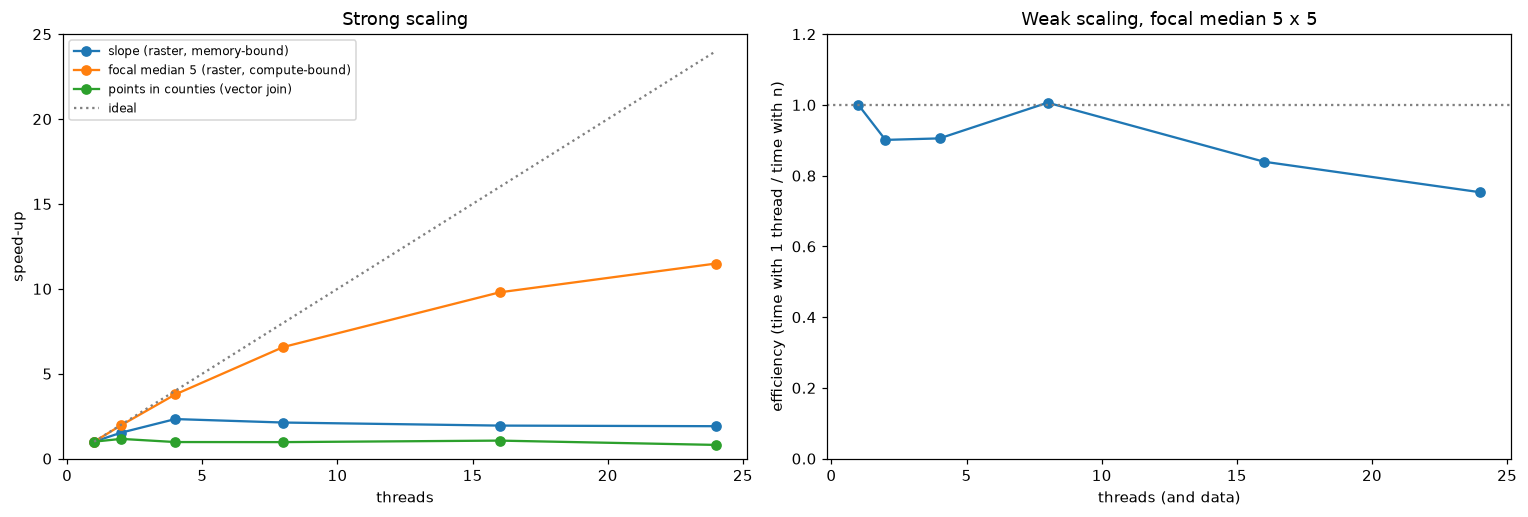

,"slope (raster, memory-bound)","focal median 5 (raster, compute-bound)",points in counties (vector join)
1,3.71,9.08,1.12
2,2.42,4.61,0.97
4,1.59,2.40,1.15
8,1.74,1.38,1.16
16,1.90,0.93,1.06
24,1.94,0.79,1.39


In [4]:
ndvi = dd.gp_raster("ndvi").compute()  # NDVI in memory, so reading does not dominate
work = {"slope (raster, memory-bound)": lambda: pdist.raster.slope(dem, compute="cpu", chunks=(1024, 1024)),  # three workloads
        "focal median 5 (raster, compute-bound)": lambda: pdist.raster.focal(dem[:6000, :6000], "median", size=5, compute="cpu", chunks=(750, 750)),
        "points in counties (vector join)": lambda: pdist.vector.sjoin(pts, ks, predicate="within", compute="cpu", npartitions=48)}
threads = [1, 2, 4, 8, 16, 24]  # thread counts
strong = pd.DataFrame(index=threads, columns=list(work), dtype=float)  # seconds
for n in threads:  # each count
    with dask.config.set(scheduler="threads", num_workers=n):  # n threads
        for name, fn in work.items():  # each workload
            fn(); t = time.perf_counter(); fn(); strong.loc[n, name] = time.perf_counter() - t  # warm, then time
weak = {}  # seconds by thread count
for n in threads:  # each count
    side = int(np.sqrt(n * 11e6))  # pixels per side so each thread has about 11 million
    sub = dem[:min(side, dem.shape[0]), :min(side, dem.shape[1])]  # the window
    with dask.config.set(scheduler="threads", num_workers=n):  # n threads
        pdist.raster.focal(sub, "median", size=5, compute="cpu", chunks=(1024, 1024))  # warm-up
        t = time.perf_counter(); pdist.raster.focal(sub, "median", size=5, compute="cpu", chunks=(1024, 1024)); weak[n] = time.perf_counter() - t  # time
fig, ax = plt.subplots(1, 2, figsize=(14, 4.8))  # two panels
for col in strong:  # strong scaling curves
    ax[0].plot(threads, strong[col].iloc[0] / strong[col], "o-", label=col)  # speed-up
ax[0].plot(threads, threads, ":", color="grey", label="ideal"); ax[0].set_ylim(0, 25)  # ideal line
ax[0].set_xlabel("threads"); ax[0].set_ylabel("speed-up"); ax[0].legend(fontsize=8); ax[0].set_title("Strong scaling")  # labels
ax[1].plot(list(weak), [weak[1] / v for v in weak.values()], "o-")  # weak scaling efficiency
ax[1].axhline(1, ls=":", color="grey"); ax[1].set_ylim(0, 1.2); ax[1].set_xlabel("threads (and data)")  # ideal
ax[1].set_ylabel("efficiency (time with 1 thread / time with n)"); ax[1].set_title("Weak scaling, focal median 5 x 5")  # labels
plt.tight_layout(); plt.show()  # draw
strong.round(2)  # the seconds

The three workloads scale very differently on the same 24 cores. The compute-bound median scales
well; slope, which mostly moves memory, stops improving after a few threads; the vector join sits
in between, because building the result table runs in one thread. Weak scaling of the median
holds up until the cores start to share memory bandwidth and the turbo clock falls with more
active cores. Measure scaling for your own workload before choosing hardware.

## Where the time goes: profiling

`pdist.profile` without a session uses Dask's local profiler and returns a table of seconds by
task type; with a session it writes Dask's HTML performance report (task stream, worker
profiles, bandwidth), which opens in a browser.

In [5]:
lazy_chain = lambda: pdist.raster.hillshade(pdist.raster.focal(dd.gp_raster("elev"), "mean", size=5, compute="cpu"), compute="cpu")  # read, smooth, shade
res, table = pdist.profile(lazy_chain)  # local profiler
print(f"result {res.shape}; task time summed over threads: {table['sum'].sum():.1f} s")  # total
print(table.head(8).round(2).to_string())  # the most expensive task types
with pdist.start("local", n_workers=4, threads_per_worker=6) as s:  # a cluster for the HTML report
    _, report = pdist.profile(lazy_chain, path=str(OUT / "profile_hillshade.html"))  # performance report
print("performance report:", report, f"({Path(report).stat().st_size / 1e6:.1f} MB)")  # where it is

result (17196, 15245); task time summed over threads: 71.3 s
                 sum  count
task                       
getitem        63.47   1517
open_rasterio   3.59      9
rechunk         1.78    162
_trim           1.05    102
concatenate     0.70    396
finalize        0.37      1
overlap         0.28     16
repeat          0.03     22


performance report: outputs/profile_hillshade.html (0.6 MB)


The table shows how the time divides between reading the GeoTIFF chunks, assembling the halos
(the `concatenate` and `getitem` tasks of `map_overlap`) and the computations themselves. Open the
HTML report to see the same as a timeline per thread.

## Seven pitfalls, reproduced and fixed

### 1. Computing the same graph twice

Each `.compute()` runs its graph from the start. Two statistics of the same lazy array computed
one after the other read the file twice; `dask.compute` (or `pdist.compute`) shares the work.

In [6]:
lazy = dd.gp_raster("preci")  # lazy
t = time.perf_counter(); a, b = float(lazy.mean()), float(lazy.std()); twice = time.perf_counter() - t  # two passes
t = time.perf_counter(); a2, b2 = dask.compute(lazy.mean(), lazy.std()); once = time.perf_counter() - t  # one shared pass
print(f"two .compute() calls {twice:.2f} s | one dask.compute {once:.2f} s | same values: {np.isclose(a, a2) and np.isclose(b, b2)}")  # result

two .compute() calls 1.81 s | one dask.compute 1.30 s | same values: True


### 2. Tiny chunks

Notebook 01 measured it: 256 pixel chunks were about nine times slower than 2048 pixel
chunks for the same slope. Check `data.npartitions` and the task count before running a big job.

### 3. Moving data to the host between GPU steps

A chain of GPU operations on host data copies every intermediate result to the host and back.
Moving the input once and keeping intermediates on the device avoids that.

In [7]:
if caps["gpus"]:  # needs a GPU
    chain = lambda d: pdist.raster.hillshade(pdist.raster.focal(d, "mean", size=5, compute="gpu"), compute="gpu")  # two GPU steps
    t = time.perf_counter(); chain(dem); sync(); host = time.perf_counter() - t  # host in, host between, host out
    t = time.perf_counter(); out = pdist.to_cpu(chain(pdist.to_gpu(dem))); sync(); device = time.perf_counter() - t  # one copy in, one out
    print(f"host input: {host:.2f} s | data kept on the GPU: {device:.2f} s")  # result

host input: 2.05 s | data kept on the GPU: 1.22 s


### 4. Reading a GPU result with NumPy

Results stay on the GPU when the input was on the GPU. NumPy cannot read CuPy memory directly;
move results with `pdist.to_cpu` (or `.get()`), and check with `pdist.is_gpu`.

In [8]:
if caps["gpus"]:  # needs a GPU
    r = pdist.raster.slope(pdist.to_gpu(win))  # a GPU result
    try:  # the mistake
        np.asarray(r.data)  # NumPy on CuPy memory
    except TypeError as e:  # what happens
        print("np.asarray on a CuPy array:", str(e)[:90])  # message
    print("is_gpu:", pdist.is_gpu(r), "| after to_cpu:", pdist.is_gpu(pdist.to_cpu(r)), type(pdist.to_cpu(r).data).__name__)  # the fix

np.asarray on a CuPy array: Implicit conversion to a NumPy array is not allowed. Please use `.get()` to construct a Nu
is_gpu: True | after to_cpu: False ndarray


### 5. `compute="auto"` on a machine with a GPU

`"auto"` picks the GPU whenever one exists, also inside the worker processes of a CPU cluster.
While writing notebook 01 this silently turned a "CPU cluster" comparison into a GPU one, and
four worker processes competed for the GPU's memory. Pass `compute="cpu"` explicitly when
measuring the CPU, or set the default for a whole session.

In [9]:
print("auto on this machine:", pdist.explain("raster.slope")["uses"])  # GPU when present
pdist.set_defaults(compute="cpu")  # every call now defaults to the CPU
print("after set_defaults(compute='cpu'):", pdist.explain("raster.slope")["uses"])  # CPU
pdist.set_defaults(compute="auto")  # back to the default

auto on this machine: gpu
after set_defaults(compute='cpu'): cpu


Defaults(compute='auto', npartitions=None, chunks='auto')

### 6. Importing cuDF or cuML changes CuPy's memory allocator

Importing `cudf` or `cuml` calls `cupy.cuda.set_allocator(rmm_cupy_allocator)`. Without an RMM
pool every CuPy allocation then becomes a `cudaMalloc`, which made chunked GPU work about four
times slower while this chapter was written, and memory already cached by CuPy's pool is
stranded. GeoLattice imports RAPIDS libraries through `geolattice.distributed._backend.rapids`,
which restores the previous allocator, and `pdist.capabilities()` only checks that the packages
are installed. If you import cuDF yourself, restore the allocator afterwards or configure an RMM
pool.

In [10]:
if caps["gpus"]:  # needs a GPU and RAPIDS
    import cupy as cp  # GPU arrays
    g = pdist.to_gpu(dem)  # the DEM on the device
    bench = lambda: pdist.benchmark(pdist.raster.slope, g, computes=("gpu",), repeats=3).best_s.iloc[0]  # GPU-only timing
    before = cp.cuda.get_allocator()  # CuPy's own pool
    t_pool = bench()  # with CuPy's pool
    import cudf  # noqa: F401  (a plain import: switches the allocator)
    switched = cp.cuda.get_allocator() is not before  # did it change?
    t_rmm = bench()  # with RMM's default allocator
    cp.cuda.set_allocator(before)  # the fix: restore CuPy's pool
    t_fixed = bench()  # again with the pool
    print(f"allocator switched by import cudf: {switched} | slope: CuPy pool {t_pool:.3f} s, after import {t_rmm:.3f} s, restored {t_fixed:.3f} s")  # result
    del g  # free GPU memory

allocator switched by import cudf: False | slope: CuPy pool 0.340 s, after import 0.341 s, restored 0.342 s


### 7. Spilling to disk

A worker that exceeds 60 % of its memory limit writes results to disk. Persisting a 1 GB DEM on
two workers limited to 400 MB each forces spilling; the same persist with enough memory does not.

In [11]:
for limit in ["400MB", "4GB"]:  # too little and enough memory per worker
    with pdist.start("local", n_workers=2, threads_per_worker=4, memory_limit=limit, dashboard=False) as s:  # small cluster
        t = time.perf_counter()  # start
        p = pdist.persist(dd.gp_raster("elev"))  # 1 GB into worker memory
        from dask.distributed import wait; wait(p.data)  # until loaded
        v = float(pdist.raster.slope(p, compute="cpu").mean())  # use it
        secs = time.perf_counter() - t  # elapsed
        spilled = sum(w.get("metrics", {}).get("spilled_bytes", {}).get("disk", 0) for w in s.client.scheduler_info()["workers"].values())  # bytes on disk
        print(f"memory limit {limit:>5} per worker: {secs:.1f} s, spilled to disk {spilled / 1e9:.2f} GB")  # result

2026-11-24 09:35:25,209 - distributed.nanny.memory - WARNING - Worker tcp://127.0.0.1:32941 (pid=1129328) exceeded 95% memory budget. Restarting...


2026-11-24 09:35:25,231 - distributed.nanny - WARNING - Restarting worker (status=Status.running)


2026-11-24 09:35:25,608 - distributed.nanny.memory - WARNING - Worker tcp://127.0.0.1:45559 (pid=1129331) exceeded 95% memory budget. Restarting...


2026-11-24 09:35:25,631 - distributed.nanny - WARNING - Restarting worker (status=Status.running)


2026-11-24 09:35:26,009 - distributed.nanny.memory - WARNING - Worker tcp://127.0.0.1:36871 (pid=1129352) exceeded 95% memory budget. Restarting...


2026-11-24 09:35:26,029 - distributed.nanny - WARNING - Restarting worker (status=Status.running)


2026-11-24 09:35:26,408 - distributed.nanny.memory - WARNING - Worker tcp://127.0.0.1:37969 (pid=1129362) exceeded 95% memory budget. Restarting...


2026-11-24 09:35:26,410 - distributed.scheduler - ERROR - Task original-open_rasterio-274c502885a65212b767c261ee6f3dd7<this-array>-249ef7c86302823635cf5d20ad853805 marked as failed because 4 workers died while trying to run it


2026-11-24 09:35:26,472 - distributed.nanny - WARNING - Restarting worker (status=Status.running)


KilledWorker: Attempted to run task 'original-open_rasterio-274c502885a65212b767c261ee6f3dd7<this-array>-249ef7c86302823635cf5d20ad853805' on 4 different workers, but all those workers died while running it. The last worker that attempt to run the task was tcp://127.0.0.1:37969. Inspecting worker logs is often a good next step to diagnose what went wrong. For more information see https://distributed.dask.org/en/stable/killed.html.

With 400 MB per worker most of the persisted DEM went to disk, and every later use read it back;
with 4 GB nothing spilled. A job that spills constantly needs more workers, more memory per
worker, smaller chunks, or less data persisted.

## Summary and exercises

- `check_equivalence` confirmed that every GPU implementation used in this chapter matched the
  CPU on real data: exactly for integers and geometries, to rounding for floating point.
- Correct timing needs warm-up, synchronisation, materialised lazy results and repeats;
  `pdist.benchmark` does all four.
- Strong scaling differed by workload: a compute-bound median scaled well, memory-bound slope
  did not, and the vector join was limited by its serial assembly step.
- `pdist.profile` attributes time to task types, or writes Dask's HTML performance report.
- Seven pitfalls reproduced: repeated computes, tiny chunks, host round trips between GPU steps,
  NumPy on GPU memory, `compute="auto"` inside CPU clusters, RAPIDS imports changing CuPy's
  allocator, and spilling.

**Exercises**

1. Add `pdist.network.shortest_path_lengths` and `pdist.analysis.dbscan` (with `compute="gpu"`)
   to the equivalence table. What tolerance does each need?
2. Measure strong scaling of `pdist.zonal_stats` for the counties with 1 to 24 threads. Where
   does it stop improving, and why?
3. Open the HTML performance report and identify the longest task in the task stream.
4. Repeat the spilling experiment with `memory_limit="1GB"`. How much spills, and how long does
   it take?